In [4]:
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tabulate import tabulate          # pip install tabulate (pre-installed on Colab)

# ──────────────────────────────────────────────────────────────
# DATASET & PARAMETERS
# ──────────────────────────────────────────────────────────────

# Delivery locations
locations = {
    "L1": {"name": "KLCC",          "distance": 9,  "weight": 8,  "priority": 5},
    "L2": {"name": "Bukit Bintang", "distance": 10, "weight": 7,  "priority": 5},
    "L3": {"name": "Cheras",        "distance": 12, "weight": 14, "priority": 4},
    "L4": {"name": "Setiawangsa",   "distance": 7,  "weight": 11, "priority": 4},
    "L5": {"name": "Wangsa Maju",   "distance": 6,  "weight": 10, "priority": 3},
    "L6": {"name": "Damansara",     "distance": 15, "weight": 9,  "priority": 3},
}

loc_ids    = list(locations.keys())                      # ["L1",...,"L6"]
names      = [locations[l]["name"]     for l in loc_ids]
distances  = np.array([locations[l]["distance"] for l in loc_ids])
weights    = np.array([locations[l]["weight"]   for l in loc_ids])
priorities = np.array([locations[l]["priority"] for l in loc_ids])
n_loc      = len(loc_ids)

# Van / algorithm parameters
VAN_CAPACITY  = 57      # kg
N_GENERATIONS = 37
N_ITERATIONS  = 37
POP_SIZE      = 6       # GA population / PSO particle count
CROSSOVER_RATE = 0.8
MUTATION_RATE  = 0.1
W   = 0.7               # PSO inertia weight
C1  = 1.5               # cognitive coefficient
C2  = 1.5               # social coefficient

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [5]:
def fitness(chromosome):
    """
    Fitness = Total Priority Score – Total Distance – Penalty
    Total Priority Score = Σ (weight_i × priority_i)  for selected locations
    Penalty = 100 × max(0, total_weight – van_capacity)
    """
    chrom = np.array(chromosome)
    total_weight    = np.dot(chrom, weights)
    priority_score  = np.dot(chrom, weights * priorities)
    total_distance  = np.dot(chrom, distances)
    extra_weight    = max(0, total_weight - VAN_CAPACITY)
    penalty         = 100 * extra_weight
    return priority_score - total_distance - penalty

def decode(chromosome):
    """Return selected location names, total weight, priority score, distance, penalty, fitness."""
    chrom           = np.array(chromosome)
    selected        = [names[i] for i in range(n_loc) if chrom[i] == 1]
    total_weight    = int(np.dot(chrom, weights))
    priority_score  = float(np.dot(chrom, weights * priorities))
    total_distance  = int(np.dot(chrom, distances))
    extra_weight    = max(0, total_weight - VAN_CAPACITY)
    penalty         = 100 * extra_weight
    fit             = priority_score - total_distance - penalty
    return selected, total_weight, priority_score, total_distance, penalty, fit

In [6]:
print("=" * 65)
print("   PART C: GENETIC ALGORITHM (GA)")
print("=" * 65)

# ── C1: Initial Population ────────────────────────────────────
print("\n── C1: Initial Population (Binary Chromosomes) ─────────────\n")

def random_chromosome(n):
    return [random.randint(0, 1) for _ in range(n)]

population = [random_chromosome(n_loc) for _ in range(POP_SIZE)]

header = ["Chromosome"] + loc_ids
rows   = [[f"C{i+1}"] + chrom for i, chrom in enumerate(population)]
print(tabulate(rows, headers=header, tablefmt="grid"))


   PART C: GENETIC ALGORITHM (GA)

── C1: Initial Population (Binary Chromosomes) ─────────────

+--------------+------+------+------+------+------+------+
| Chromosome   |   L1 |   L2 |   L3 |   L4 |   L5 |   L6 |
+==============+======+======+======+======+======+======+
| C1           |    0 |    0 |    1 |    0 |    0 |    0 |
+--------------+------+------+------+------+------+------+
| C2           |    0 |    0 |    1 |    0 |    0 |    0 |
+--------------+------+------+------+------+------+------+
| C3           |    0 |    0 |    0 |    0 |    1 |    0 |
+--------------+------+------+------+------+------+------+
| C4           |    1 |    1 |    0 |    0 |    1 |    1 |
+--------------+------+------+------+------+------+------+
| C5           |    1 |    0 |    0 |    1 |    0 |    0 |
+--------------+------+------+------+------+------+------+
| C6           |    1 |    0 |    1 |    1 |    1 |    0 |
+--------------+------+------+------+------+------+------+


In [7]:
print("\n── C2: Fitness Calculation for Initial Population ───────────\n")

fit_header = ["Chromosome", "Selected Locations",
              "Total Weight", "Total Priority Score",
              "Total Distance", "Penalty", "Fitness"]
fit_rows = []
for i, chrom in enumerate(population):
    sel, tw, ps, td, pen, fit_val = decode(chrom)
    fit_rows.append([
        f"C{i+1}",
        ", ".join(sel) if sel else "None",
        f"{tw} kg", f"{ps:.1f}", f"{td} km",
        f"{pen:.1f}", f"{fit_val:.1f}"
    ])
print(tabulate(fit_rows, headers=fit_header, tablefmt="grid"))


── C2: Fitness Calculation for Initial Population ───────────

+--------------+---------------------------------------------+----------------+------------------------+------------------+-----------+-----------+
| Chromosome   | Selected Locations                          | Total Weight   |   Total Priority Score | Total Distance   |   Penalty |   Fitness |
+==============+=============================================+================+========================+==================+===========+===========+
| C1           | Cheras                                      | 14 kg          |                     56 | 12 km            |         0 |        44 |
+--------------+---------------------------------------------+----------------+------------------------+------------------+-----------+-----------+
| C2           | Cheras                                      | 14 kg          |                     56 | 12 km            |         0 |        44 |
+--------------+--------------------------------

In [8]:
print("\n── C3: Selection → Crossover → Mutation ─────────────────────\n")

def tournament_selection(pop, k=2):
    """Tournament selection: pick k random individuals, return the fittest."""
    contestants = random.sample(pop, k)
    return max(contestants, key=fitness)

def single_point_crossover(p1, p2):
    if random.random() < CROSSOVER_RATE:
        point = random.randint(1, n_loc - 1)
        c1 = p1[:point] + p2[point:]
        c2 = p2[:point] + p1[point:]
        return c1, c2
    return p1[:], p2[:]   # no crossover → copies

def mutate(chrom):
    result = chrom[:]
    for i in range(len(result)):
        if random.random() < MUTATION_RATE:
            result[i] = 1 - result[i]   # bit-flip
    return result

p1 = tournament_selection(population)
p2 = tournament_selection(population)
child1, child2 = single_point_crossover(p1, p2)
child1_mut = mutate(child1)
child2_mut = mutate(child2)

demo = [
    ["Parent 1",         " ".join(map(str, p1))],
    ["Parent 2",         " ".join(map(str, p2))],
    ["Child 1 (after crossover)", " ".join(map(str, child1))],
    ["Child 2 (after crossover)", " ".join(map(str, child2))],
    ["Child 1 (after mutation)",  " ".join(map(str, child1_mut))],
    ["Child 2 (after mutation)",  " ".join(map(str, child2_mut))],
]
print(tabulate(demo, headers=["Step", f"Binary ({' '.join(loc_ids)})"], tablefmt="grid"))
print(f"\n  Crossover rate: {CROSSOVER_RATE}  |  Mutation rate: {MUTATION_RATE}")



── C3: Selection → Crossover → Mutation ─────────────────────

+---------------------------+------------------------------+
| Step                      | Binary (L1 L2 L3 L4 L5 L6)   |
+===========================+==============================+
| Parent 1                  | 1 0 1 1 1 0                  |
+---------------------------+------------------------------+
| Parent 2                  | 1 0 0 1 0 0                  |
+---------------------------+------------------------------+
| Child 1 (after crossover) | 1 0 1 1 1 0                  |
+---------------------------+------------------------------+
| Child 2 (after crossover) | 1 0 0 1 0 0                  |
+---------------------------+------------------------------+
| Child 1 (after mutation)  | 1 0 1 1 1 0                  |
+---------------------------+------------------------------+
| Child 2 (after mutation)  | 1 1 0 1 1 0                  |
+---------------------------+------------------------------+

  Crossover rate: 0.

In [9]:
print(f"\n── C4: Running GA for {N_GENERATIONS} Generations ──────────\n")

ga_best_per_gen = []

def ga_run():
    pop = [random_chromosome(n_loc) for _ in range(POP_SIZE)]

    for gen in range(N_GENERATIONS):
        new_pop = []
        while len(new_pop) < POP_SIZE:
            p1 = tournament_selection(pop)
            p2 = tournament_selection(pop)
            c1_chrom, c2_chrom = single_point_crossover(p1, p2)
            c1_chrom = mutate(c1_chrom)
            c2_chrom = mutate(c2_chrom)
            new_pop.extend([c1_chrom, c2_chrom])

        # Elitism: keep the best individual from previous generation
        best_prev = max(pop, key=fitness)
        new_pop = new_pop[:POP_SIZE]
        worst_idx = min(range(POP_SIZE), key=lambda i: fitness(new_pop[i]))
        new_pop[worst_idx] = best_prev
        pop = new_pop

        best_fit = max(fitness(c) for c in pop)
        ga_best_per_gen.append(best_fit)

    return max(pop, key=fitness)

ga_best = ga_run()
sel, tw, ps, td, pen, fit_val = decode(ga_best)

print(f"  Best Chromosome  : {ga_best}")
print(f"  Selected Locations: {', '.join(sel)}")
print(f"  Total Weight      : {tw} kg  (Van capacity: {VAN_CAPACITY} kg)")
print(f"  Total Priority Score: {ps:.1f}")
print(f"  Total Distance    : {td} km")
print(f"  Penalty           : {pen:.1f}")
print(f"  Final Fitness     : {fit_val:.1f}")



── C4: Running GA for 37 Generations ──────────

  Best Chromosome  : [1, 1, 1, 1, 1, 0]
  Selected Locations: KLCC, Bukit Bintang, Cheras, Setiawangsa, Wangsa Maju
  Total Weight      : 50 kg  (Van capacity: 57 kg)
  Total Priority Score: 205.0
  Total Distance    : 44 km
  Penalty           : 0.0
  Final Fitness     : 161.0


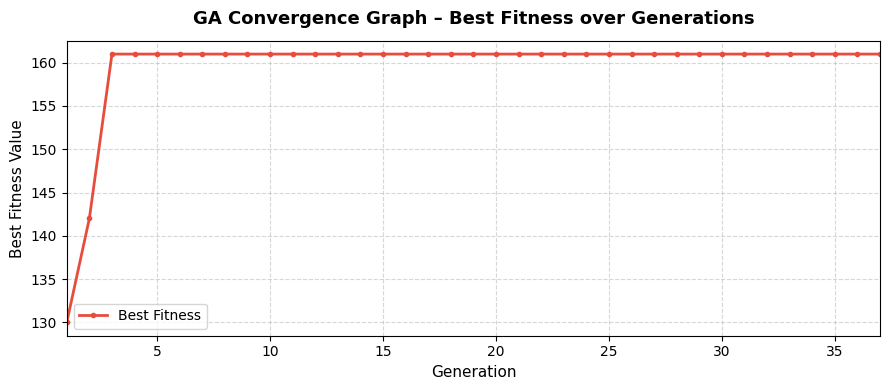

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, N_GENERATIONS + 1), ga_best_per_gen,
        color="#E74C3C", linewidth=2, marker="o", markersize=3, label="Best Fitness")
ax.set_title("GA Convergence Graph – Best Fitness over Generations",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Generation", fontsize=11)
ax.set_ylabel("Best Fitness Value", fontsize=11)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlim(1, N_GENERATIONS)
plt.tight_layout()
plt.savefig("ga_convergence.png", dpi=150)
plt.show()



In [11]:
print("\n" + "=" * 65)
print("   PART D: BINARY PARTICLE SWARM OPTIMIZATION (Binary PSO)")
print("=" * 65)

# ── D1: Initial Particles ─────────────────────────────────────
print("\n── D1: Initial Particles (Binary Positions) ─────────────────\n")

def random_particle():
    pos = np.array([random.randint(0, 1) for _ in range(n_loc)], dtype=float)
    vel = np.array([random.uniform(-1, 1)  for _ in range(n_loc)])
    return pos, vel

particles_pos = []
particles_vel = []
for _ in range(POP_SIZE):
    p, v = random_particle()
    particles_pos.append(p)
    particles_vel.append(v)

header_d1 = ["Particle"] + loc_ids
rows_d1 = [[f"P{i+1}"] + list(map(int, p)) for i, p in enumerate(particles_pos)]
print(tabulate(rows_d1, headers=header_d1, tablefmt="grid"))


   PART D: BINARY PARTICLE SWARM OPTIMIZATION (Binary PSO)

── D1: Initial Particles (Binary Positions) ─────────────────

+------------+------+------+------+------+------+------+
| Particle   |   L1 |   L2 |   L3 |   L4 |   L5 |   L6 |
+============+======+======+======+======+======+======+
| P1         |    0 |    1 |    0 |    1 |    0 |    1 |
+------------+------+------+------+------+------+------+
| P2         |    0 |    0 |    0 |    0 |    1 |    1 |
+------------+------+------+------+------+------+------+
| P3         |    1 |    1 |    0 |    0 |    1 |    1 |
+------------+------+------+------+------+------+------+
| P4         |    0 |    1 |    0 |    0 |    1 |    0 |
+------------+------+------+------+------+------+------+
| P5         |    1 |    1 |    0 |    0 |    1 |    1 |
+------------+------+------+------+------+------+------+
| P6         |    0 |    0 |    0 |    0 |    0 |    0 |
+------------+------+------+------+------+------+------+


In [12]:
print("\n── D2: PSO Parameters ───────────────────────────────────────\n")
params = [
    ["Number of particles",  POP_SIZE],
    ["Number of iterations", N_ITERATIONS],
    ["Inertia weight (w)",   W],
    ["Cognitive coeff (c1)", C1],
    ["Social coeff (c2)",    C2],
]
print(tabulate(params, headers=["Parameter", "Value"], tablefmt="grid"))



── D2: PSO Parameters ───────────────────────────────────────

+----------------------+---------+
| Parameter            |   Value |
+======================+=========+
| Number of particles  |     6   |
+----------------------+---------+
| Number of iterations |    37   |
+----------------------+---------+
| Inertia weight (w)   |     0.7 |
+----------------------+---------+
| Cognitive coeff (c1) |     1.5 |
+----------------------+---------+
| Social coeff (c2)    |     1.5 |
+----------------------+---------+


In [13]:
print("\n── D3: PSO Concepts Summary ─────────────────────────────────\n")
print("""  • Position  : Binary vector (0/1) indicating selected delivery locations.
  • Velocity  : Continuous value influencing the probability of flipping bits.
  • Sigmoid   : Converts velocity → probability: σ(v) = 1 / (1 + e^(−v)).
                If rand() < σ(v_i), bit i is set to 1, else 0.
  • pBest     : Best position found by an individual particle so far.
  • gBest     : Best position found by ANY particle (global best).
  • Update    : v(t+1) = w·v(t) + c1·r1·(pBest−x) + c2·r2·(gBest−x)
                x(t+1) = 1  if rand() < sigmoid(v(t+1)),  else 0
""")



── D3: PSO Concepts Summary ─────────────────────────────────

  • Position  : Binary vector (0/1) indicating selected delivery locations.
  • Velocity  : Continuous value influencing the probability of flipping bits.
  • Sigmoid   : Converts velocity → probability: σ(v) = 1 / (1 + e^(−v)).
                If rand() < σ(v_i), bit i is set to 1, else 0.
  • pBest     : Best position found by an individual particle so far.
  • gBest     : Best position found by ANY particle (global best).
  • Update    : v(t+1) = w·v(t) + c1·r1·(pBest−x) + c2·r2·(gBest−x)
                x(t+1) = 1  if rand() < sigmoid(v(t+1)),  else 0



In [14]:
print(f"── D4: Running Binary PSO for {N_ITERATIONS} Iterations ─────\n")

def sigmoid(v):
    return 1 / (1 + np.exp(-np.clip(v, -500, 500)))

# Re-initialise
pos  = [np.array([random.randint(0,1) for _ in range(n_loc)], dtype=float) for _ in range(POP_SIZE)]
vel  = [np.array([random.uniform(-1,1) for _ in range(n_loc)])              for _ in range(POP_SIZE)]
pBest     = [p.copy() for p in pos]
pBest_fit = [fitness(p) for p in pos]
gBest     = pBest[np.argmax(pBest_fit)].copy()
gBest_fit = max(pBest_fit)

pso_best_per_iter = []

for it in range(N_ITERATIONS):
    for i in range(POP_SIZE):
        r1 = np.random.rand(n_loc)
        r2 = np.random.rand(n_loc)
        vel[i] = (W * vel[i]
                  + C1 * r1 * (pBest[i] - pos[i])
                  + C2 * r2 * (gBest    - pos[i]))
        # Update position using sigmoid
        prob = sigmoid(vel[i])
        pos[i] = np.where(np.random.rand(n_loc) < prob, 1.0, 0.0)

        f = fitness(pos[i])
        if f > pBest_fit[i]:
            pBest[i]     = pos[i].copy()
            pBest_fit[i] = f
        if f > gBest_fit:
            gBest     = pos[i].copy()
            gBest_fit = f

    pso_best_per_iter.append(gBest_fit)

sel_p, tw_p, ps_p, td_p, pen_p, fit_p = decode(gBest)
print(f"  Best Particle     : {list(map(int, gBest))}")
print(f"  Selected Locations: {', '.join(sel_p)}")
print(f"  Total Weight      : {tw_p} kg  (Van capacity: {VAN_CAPACITY} kg)")
print(f"  Total Priority Score: {ps_p:.1f}")
print(f"  Total Distance    : {td_p} km")
print(f"  Penalty           : {pen_p:.1f}")
print(f"  Final Fitness     : {fit_p:.1f}")

# ── Particle table (final positions) ─────────────────────────
print("\n  Final Particle Positions:\n")
rows_final = [[f"P{i+1}"] + list(map(int, pos[i])) for i in range(POP_SIZE)]
print(tabulate(rows_final, headers=["Particle"] + loc_ids, tablefmt="grid"))


── D4: Running Binary PSO for 37 Iterations ─────

  Best Particle     : [1, 1, 1, 1, 1, 0]
  Selected Locations: KLCC, Bukit Bintang, Cheras, Setiawangsa, Wangsa Maju
  Total Weight      : 50 kg  (Van capacity: 57 kg)
  Total Priority Score: 205.0
  Total Distance    : 44 km
  Penalty           : 0.0
  Final Fitness     : 161.0

  Final Particle Positions:

+------------+------+------+------+------+------+------+
| Particle   |   L1 |   L2 |   L3 |   L4 |   L5 |   L6 |
+============+======+======+======+======+======+======+
| P1         |    1 |    1 |    0 |    1 |    0 |    0 |
+------------+------+------+------+------+------+------+
| P2         |    1 |    1 |    0 |    1 |    0 |    1 |
+------------+------+------+------+------+------+------+
| P3         |    1 |    1 |    1 |    1 |    1 |    0 |
+------------+------+------+------+------+------+------+
| P4         |    1 |    0 |    0 |    1 |    1 |    1 |
+------------+------+------+------+------+------+------+
| P5        

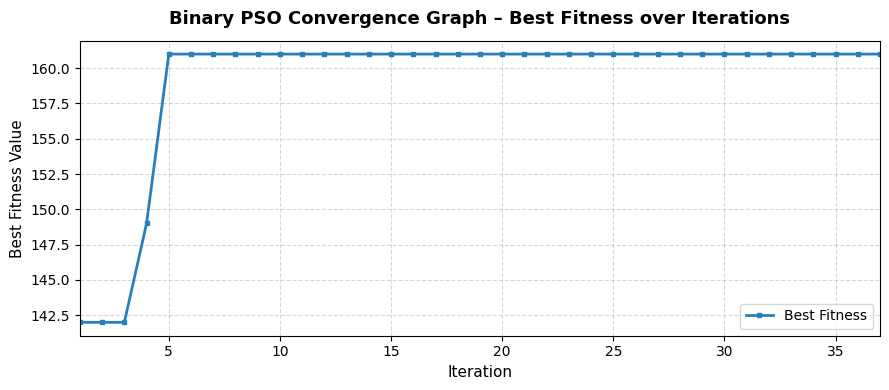

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, N_ITERATIONS + 1), pso_best_per_iter,
        color="#2980B9", linewidth=2, marker="s", markersize=3, label="Best Fitness")
ax.set_title("Binary PSO Convergence Graph – Best Fitness over Iterations",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Iteration", fontsize=11)
ax.set_ylabel("Best Fitness Value", fontsize=11)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xlim(1, N_ITERATIONS)
plt.tight_layout()
plt.savefig("pso_convergence.png", dpi=150)
plt.show()




   PART E: GA vs Binary PSO Comparison

+------------------------------+-------------+--------------+--------------------+
| Criteria                     | GA Result   | PSO Result   | Better Algorithm   |
+==============================+=============+==============+====================+
| Best fitness value           | 161.0       | 161.0        | Tie                |
+------------------------------+-------------+--------------+--------------------+
| Total parcel weight (kg)     | 50          | 50           | Tie                |
+------------------------------+-------------+--------------+--------------------+
| Total priority score         | 205.0       | 205.0        | Tie                |
+------------------------------+-------------+--------------+--------------------+
| Total distance (km)          | 44          | 44           | Tie                |
+------------------------------+-------------+--------------+--------------------+
| Number of selected locations | 5           |

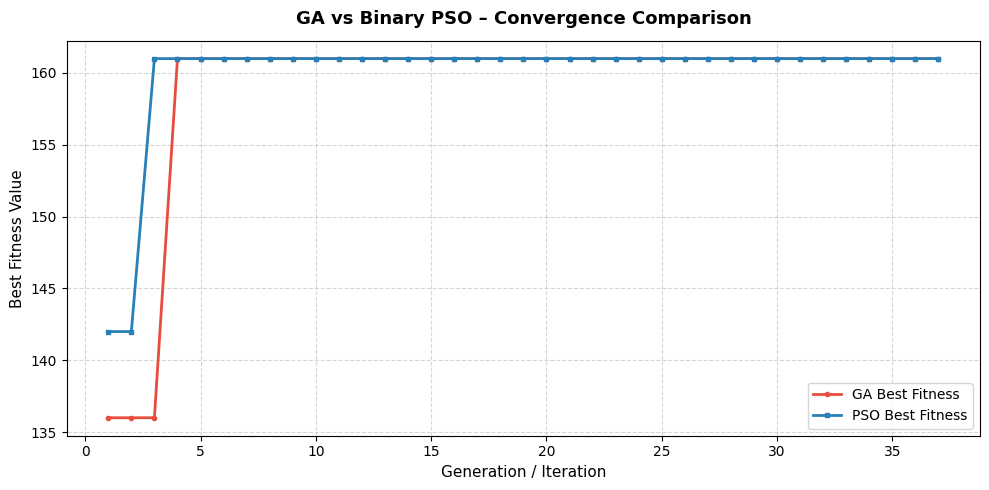

In [22]:
print("\n" + "=" * 65)
print("   PART E: GA vs Binary PSO Comparison")
print("=" * 65 + "\n")

# ── Re-run GA (in case Part E is executed as a standalone cell) ──
def _ga_operators_e():
    def _sel(pop):
        return max(random.sample(pop, 2), key=fitness)
    def _cx(p1, p2):
        if random.random() < CROSSOVER_RATE:
            pt = random.randint(1, n_loc - 1)
            return p1[:pt]+p2[pt:], p2[:pt]+p1[pt:]
        return p1[:], p2[:]
    def _mut(c):
        r = c[:]
        for i in range(len(r)):
            if random.random() < MUTATION_RATE:
                r[i] = 1 - r[i]
        return r
    random.seed(SEED); np.random.seed(SEED)
    pop = [random_chromosome(n_loc) for _ in range(POP_SIZE)]
    ga_hist = []
    for _ in range(N_GENERATIONS):
        new_pop = []
        while len(new_pop) < POP_SIZE:
            c1e, c2e = _cx(_sel(pop), _sel(pop))
            new_pop.extend([_mut(c1e), _mut(c2e)])
        best_prev = max(pop, key=fitness)
        new_pop = new_pop[:POP_SIZE]
        new_pop[min(range(POP_SIZE), key=lambda i: fitness(new_pop[i]))] = best_prev
        pop = new_pop
        ga_hist.append(max(fitness(c) for c in pop))
    return max(pop, key=fitness), ga_hist

def _pso_e():
    def _sig(v):
        return 1 / (1 + np.exp(-np.clip(v, -500, 500)))
    random.seed(SEED); np.random.seed(SEED)
    pos_e  = [np.array([random.randint(0,1) for _ in range(n_loc)], dtype=float) for _ in range(POP_SIZE)]
    vel_e  = [np.array([random.uniform(-1,1) for _ in range(n_loc)]) for _ in range(POP_SIZE)]
    pb     = [p.copy() for p in pos_e]
    pbf    = [fitness(p) for p in pos_e]
    gb     = pb[int(np.argmax(pbf))].copy()
    gbf    = max(pbf)
    pso_hist = []
    for _ in range(N_ITERATIONS):
        for i in range(POP_SIZE):
            r1e = np.random.rand(n_loc); r2e = np.random.rand(n_loc)
            vel_e[i] = W*vel_e[i] + C1*r1e*(pb[i]-pos_e[i]) + C2*r2e*(gb-pos_e[i])
            pos_e[i] = np.where(np.random.rand(n_loc) < _sig(vel_e[i]), 1.0, 0.0)
            f = fitness(pos_e[i])
            if f > pbf[i]: pb[i]=pos_e[i].copy(); pbf[i]=f
            if f > gbf:    gb=pos_e[i].copy();    gbf=f
        pso_hist.append(gbf)
    return gb, pso_hist

_ga_best_e,  ga_best_per_gen_e  = _ga_operators_e()
_pso_best_e, pso_best_per_iter_e = _pso_e()

# Decode both results
sel,   tw,   ps,   td,   pen,   fit_val = decode(_ga_best_e)
sel_p, tw_p, ps_p, td_p, pen_p, fit_p  = decode(_pso_best_e)

ga_exceed  = "Yes" if tw   > VAN_CAPACITY else "No"
pso_exceed = "Yes" if tw_p > VAN_CAPACITY else "No"

def _better(a, b, higher_is_better=True):
    """Return 'GA', 'PSO', or 'Tie' based on comparison."""
    if a == b:
        return "Tie"
    if higher_is_better:
        return "GA" if a > b else "PSO"
    else:
        return "GA" if a < b else "PSO"

exceed_better = "Tie" if ga_exceed == pso_exceed else ("GA" if ga_exceed == "No" else "PSO")
loc_better    = "Tie" if len(sel) == len(sel_p) else ("GA" if len(sel) > len(sel_p) else "PSO")

cmp = [
    ["Best fitness value",           f"{fit_val:.1f}", f"{fit_p:.1f}",
     _better(fit_val, fit_p, higher_is_better=True)],
    ["Total parcel weight (kg)",     tw,               tw_p,
     _better(tw, tw_p, higher_is_better=False)],
    ["Total priority score",         f"{ps:.1f}",      f"{ps_p:.1f}",
     _better(ps, ps_p, higher_is_better=True)],
    ["Total distance (km)",          td,               td_p,
     _better(td, td_p, higher_is_better=False)],
    ["Number of selected locations", len(sel),         len(sel_p),   loc_better],
    ["Exceeded van capacity?",       ga_exceed,        pso_exceed,   exceed_better],
]
print(tabulate(cmp,
               headers=["Criteria", "GA Result", "PSO Result", "Better Algorithm"],
               tablefmt="grid"))

# ── Combined Convergence Plot ─────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, N_GENERATIONS + 1), ga_best_per_gen_e,
        color="#E74C3C", linewidth=2, label="GA Best Fitness",  marker="o", markersize=3)
ax.plot(range(1, N_ITERATIONS + 1), pso_best_per_iter_e,
        color="#2980B9", linewidth=2, label="PSO Best Fitness", marker="s", markersize=3)
ax.set_title("GA vs Binary PSO – Convergence Comparison",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Generation / Iteration", fontsize=11)
ax.set_ylabel("Best Fitness Value", fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("ga_vs_pso_convergence.png", dpi=150)
plt.show()
